# **009 Importing TensorFlow 2**

## **1. Problem**

### Idnetifying the breed of a dog, given an image of a dog.

### When I'm sitting at the cafe and I take a photo of a dof, I want to know what breed of dog it is.

## **2. Data**

### The data we are using is from kaggle's dog breed identification competition.

### https://www.kaggle.com/competitions/dog-breed-identification/data


## **3. Evaluation**

### The evaluation is a file with prediction probabilities for each dog breed of each test image

### https://www.kaggle.com/competitions/dog-breed-identification/overview/evaluation

## **4. Feature**
### Some information about the data:
* #### We're dealing with images (unstructured data), so it's best we use deep learning/transfer learning.
* #### There are 120 breeds of dogs(this means  there are 120 difft classes).
* #### There around 10000+ images in the training set (these images have labels).
* #### There are around 10000+ images in the test set (these images have no labels, bcos we'll want to predict them).


# **Get our workspace ready**

### **Import TensorFlow**
* This is what we will use to build the pipeline for the model and get our data into tensors

### **Import TensorFlow Hub**
* The reason we need tensorflow hub is bcos that is where we will pick our model

### **Make sure we're using a GPU**
* Working with neural networks, requires more computing power, hence we need a GPU, which is much more efficient for this kind of work

## **Import necessary tools:**
### Now for this, i am using a CPU on my laptop to create an initial model by using **`1000`** dataset b4 going to run the full model on a GPU

In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tensorflow_hub as hub
import tf_keras

print("TF version:", tf.__version__)
print("TF Hub version:", hub.__version__)
print("Keras version:", tf_keras.__version__) 
print("Model file exists:", os.path.exists("dog_vision_model.keras"))

C:\Users\HP\miniconda3\envs\dog-vision\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TF version: 2.21.0
TF Hub version: 0.16.1
Keras version: 2.21.0
Model file exists: True


# **014 Loading Our Data Labels**

## **Getting our data ready (turning into Tensors)**
#### With all ML models, our data has to be in numerical format. So that's what we'll be doing first. Turning our images into Tensors (numerical representation).

### **Let's start by accessing our data and checking our label**

### **Checkout the labels of our data:**
### **Temple:** Now, i can read the labels.csv directly bcos i mistakenly created my **env (`which is dog-vision`)** not **`env`** this time in the systems folder. It's not good for me as since i am learning i can be confused.

In [2]:
import pandas as pd

# The exact path matching your Kaggle storage layout
labels_csv = pd.read_csv("labels.csv")

print(labels_csv.describe())

                                      id               breed
count                              10222               10222
unique                             10222                 120
top     000bec180eb18c7604dcecc8fe0dba07  scottish_deerhound
freq                                   1                 126


In [3]:
print(labels_csv.head())

                                 id             breed
0  000bec180eb18c7604dcecc8fe0dba07       boston_bull
1  001513dfcb2ffafc82cccf4d8bbaba97             dingo
2  001cdf01b096e06d78e9e5112d419397          pekinese
3  00214f311d5d2247d5dfe4fe24b2303d          bluetick
4  0021f9ceb3235effd7fcde7f7538ed62  golden_retriever


#### **How many images are there of each breed?**

In [4]:
labels_csv["breed"].value_counts()

breed
scottish_deerhound      126
maltese_dog             117
afghan_hound            116
entlebucher             115
bernese_mountain_dog    114
                       ... 
golden_retriever         67
komondor                 67
brabancon_griffon        67
eskimo_dog               66
briard                   66
Name: count, Length: 120, dtype: int64

#### **Visualizing the above on a plot**

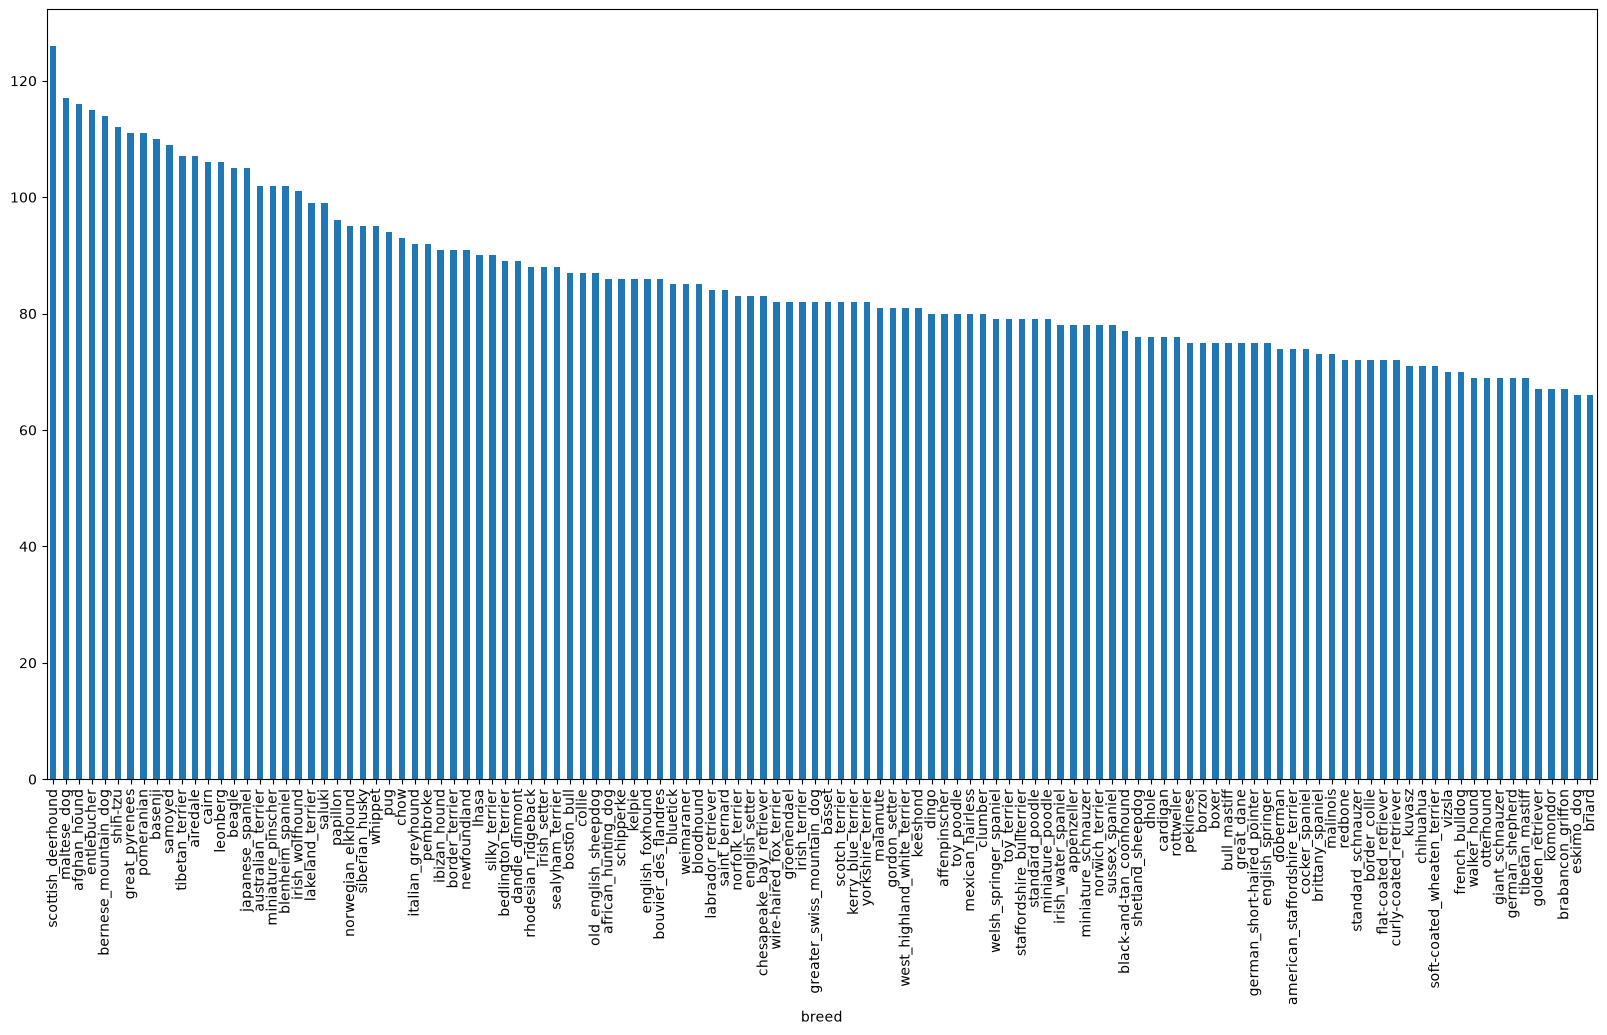

In [5]:
labels_csv["breed"].value_counts().plot(kind="bar", figsize=(20, 10))
# OR
labels_csv["breed"].value_counts().plot.bar(figsize=(20, 10));

In [6]:
labels_csv["breed"].value_counts().median()

np.float64(82.0)

#### The **`middle`** number being **`82`** is a good thing. Just imagine, if we had, let's say **`500 images of Scottish deerhound`** and we had only **`3 images of eskimo_dog`**. We could imagine that our ML model might do very well at figuring out what **`Scottish deerhound`** looks like bcos it has so many examples. But as for an **`eskimo_dog`** it's probably going to be a bit hard to figure out what it looks like bcos it has only **`3 image`**.

### **U might be asking urself, how many images should i have per class?**

#### Google recommends a bare minimum of **`10`** per class/labels.

#### So our dataset has about **`82`** images per class which is pretty well spread out.

# **015 Preparing The Images**
### **Let's view an image**

In [7]:
from IPython.display import Image

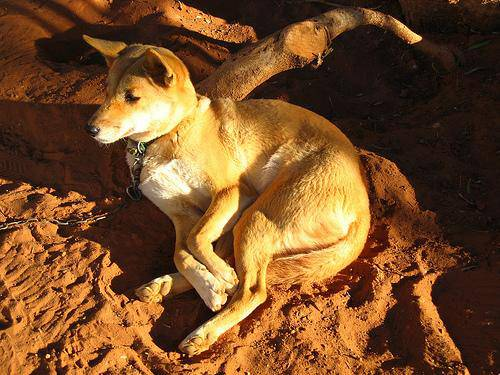

In [8]:
Image("train/001513dfcb2ffafc82cccf4d8bbaba97.jpg")

### **Getting Images and their Labels**
##### Let's get a list of all our image file pathnames.

In [9]:
labels_csv.head()

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


### **Create pathnames from image ID's**

### The purpose is to create the file path for every dog image automatically, instead of typing each image path manually.

### Remember, your labels.csv contains an id column with image IDs, such as: **`001513dfcb2ffafc82cccf4d8bbaba97`**

### But the actual image file is stored as: **`train/001513dfcb2ffafc82cccf4d8bbaba97.jpg`**

### The code adds train/ to the beginning and .jpg to the end of every ID.

In [10]:
filenames = ["train/" + fname + ".jpg" for fname in labels_csv["id"]]
# The above code is saying create a list of fname for fname in label_csv "id" column

# This is the equivalent of the code above
filenames = []
for fname in labels_csv["id"]: # for fname in labels_csv["id"] — goes through every image ID in the id 
    # column.
    filenames.append("train/" + fname + ".jpg")
    # "train/" + fname + ".jpg"— creates the path to each image by adding the folder name and file
    # extension.


# Check the first 10
filenames[:10]

['train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 'train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 'train/001cdf01b096e06d78e9e5112d419397.jpg',
 'train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 'train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 'train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 'train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 'train/002a283a315af96eaea0e28e7163b21b.jpg',
 'train/003df8b8a8b05244b1d920bb6cf451f9.jpg',
 'train/0042188c895a2f14ef64a918ed9c7b64.jpg']

##### **So now, we've got a list of all the `file names` from the `id` column of the `label_csv`, what we should do is compare them with the number of files in our training data directory, `Why?` This is to make sure that we've got the same amount of `file names` as we have in our `training file` i.e we want to maske sure that we are working with the same amount of data**

#### **Check whether number of `file names` actually matches the number `image files`**

In [11]:
import os

len(os.listdir('train'))

10222

In [12]:
if len(os.listdir("train")) == len(filenames):
  print("Filenames match actual amount of files!!! Proceed.")
else:
  print("Filenames do not macth actual amount of files, check the target directory")

Filenames match actual amount of files!!! Proceed.


### **One more check**

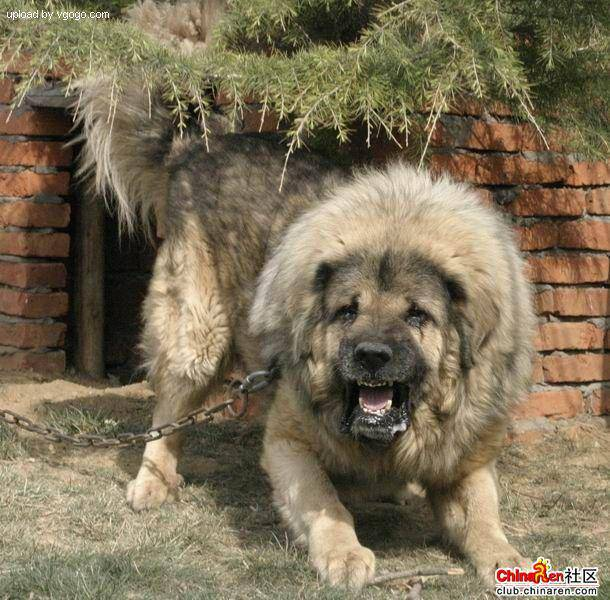

In [13]:
Image(filenames[9000])

#### **Let's see what kind of dog is above**

In [14]:
labels_csv["breed"][9000]

'tibetan_mastiff'

# **016 Turning Data Labels Into Numbers**
### Since we've now got our training image filepaths in a list, let's prepare our labels

In [15]:
import numpy as np

labels = labels_csv["breed"].to_numpy()
# OR
labels = np.array(labels)
labels

array(['boston_bull', 'dingo', 'pekinese', ..., 'airedale',
       'miniature_pinscher', 'chesapeake_bay_retriever'],
      shape=(10222,), dtype=object)

In [16]:
len(labels)

10222

## **Check if number of labels matches the number of filenames**

In [17]:
if len(labels) == len(filenames):
  print("Number of labels matches number of filenames!")
else:
  print("Number of labels does not match number of filenames, check data directories")

Number of labels matches number of filenames!


## **Now, since the ML model can't take strings as input (this is what labels currently is `labels`), what we have to do is to convert it into numbers. So how might we do this?**

#### **1) Find the unique label values**
#### This creates an array of all the different breeds, without duplicates, in sorted order.

In [18]:
unique_breeds = np.unique(labels)
unique_breeds

array(['affenpinscher', 'afghan_hound', 'african_hunting_dog', 'airedale',
       'american_staffordshire_terrier', 'appenzeller',
       'australian_terrier', 'basenji', 'basset', 'beagle',
       'bedlington_terrier', 'bernese_mountain_dog',
       'black-and-tan_coonhound', 'blenheim_spaniel', 'bloodhound',
       'bluetick', 'border_collie', 'border_terrier', 'borzoi',
       'boston_bull', 'bouvier_des_flandres', 'boxer',
       'brabancon_griffon', 'briard', 'brittany_spaniel', 'bull_mastiff',
       'cairn', 'cardigan', 'chesapeake_bay_retriever', 'chihuahua',
       'chow', 'clumber', 'cocker_spaniel', 'collie',
       'curly-coated_retriever', 'dandie_dinmont', 'dhole', 'dingo',
       'doberman', 'english_foxhound', 'english_setter',
       'english_springer', 'entlebucher', 'eskimo_dog',
       'flat-coated_retriever', 'french_bulldog', 'german_shepherd',
       'german_short-haired_pointer', 'giant_schnauzer',
       'golden_retriever', 'gordon_setter', 'great_dane',
      

In [19]:
len(unique_breeds)

120

#### **2) Turn every label into a boolean**
#### **i) Turn a single label into an array of booleans to see how it goes**
#### We compare one label with every breed because we want to identify which position represents that dog's correct breed.

In [20]:
print(labels[0])
labels[0] == unique_breeds

boston_bull


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

#### **ii) Turning every label into a boolean array**

In [21]:
boolean_labels = [label == unique_breeds for label in labels]
# The above code is just the same as 'labels[0] == unique_breeds' above, just
# that were looping over all labels
boolean_labels[:2]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([False, False, False, False, False, Fal

In [22]:
len(boolean_labels)

10222

#### **3) Turning all boolean arrays into integers**
#### **i) Example: Turning boolean array to integer**

In [23]:
print(labels[0]) # original label
print(np.where(unique_breeds == labels[0])) # index where label occurs

print(boolean_labels[0].argmax()) # .argmax() returns the position of the True value 
# in boolean array. In the example above, it returns 1.

print(boolean_labels[0].astype(int)) # .astype(int) converts False to 0 and True to 1,
# producing [0, 1, 0, ...]. There will be a 1 where the sample label occurs

boston_bull
(array([19]),)
19
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


In [24]:
filenames[:10]

['train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 'train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 'train/001cdf01b096e06d78e9e5112d419397.jpg',
 'train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 'train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 'train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 'train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 'train/002a283a315af96eaea0e28e7163b21b.jpg',
 'train/003df8b8a8b05244b1d920bb6cf451f9.jpg',
 'train/0042188c895a2f14ef64a918ed9c7b64.jpg']

### **The above filenames are not numeric yet, but we can change them using TensorFlow**

# **017 Creating Our Own Validation Set**
## **Creating our own validation set**
### Now since the dataset from kaggle doesn't come with a validation set, we're going to create our own.

### We need a validation set so we can train our model on it b4 we use it on the test set. **`A validation set helps you tune your model and check for overfitting before running it on the final test set.`**


In [25]:
# Setup X & y variables
X = filenames
y = boolean_labels

## **Worthy of Note:**
#### Since we are working on 10000+ images, it's a good idea to start working with a portion of them first to make sure things are working b4 we go and train a ML model on all of them.

#### **Now the above is for all ML projects, not just for this our images problem**

### **We're going to start off experimenting with ~1000 images and increase as needed.**

### **1) Set number of images to use for experimenting**

In [26]:
NUM_IMAGES = 1000 #@param {type:"slider", min:1000, max:10000, step:100}
# we capitalize NUM_IMAGES because it is a constant—a variable whose value is set at the beginning and never changes while the code is running.

#### **The code comment #@param {type:"slider", min:1000, max:1000, step:100} is a special syntax used in Google Colab to turn a standard code variable into an interactive UI slider.**

### **2) Let's split our data into train and validation sets**

In [27]:
from sklearn.model_selection import train_test_split

# split them into training and validation of total size NUM_IMAGES
X_train, X_val, y_train, y_val = train_test_split(X[:NUM_IMAGES],
                                                    y[:NUM_IMAGES],
                                                    test_size=0.2,
                                                    random_state=42)
# random_state=42 is the same as setting np.random.seed(42)
# Always note that y takes the labels of any ML model

len(X_train), len(y_train), len(X_val), len(y_val)

(800, 800, 200, 200)

In [28]:
# Let's have a geez at the training data
X_train[:5], y_train[:2]

(['train/00bee065dcec471f26394855c5c2f3de.jpg',
  'train/0d2f9e12a2611d911d91a339074c8154.jpg',
  'train/1108e48ce3e2d7d7fb527ae6e40ab486.jpg',
  'train/0dc3196b4213a2733d7f4bdcd41699d3.jpg',
  'train/146fbfac6b5b1f0de83a5d0c1b473377.jpg'],
 [array([False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False,  True,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, Fa

# **018 Preprocess Images**

### **Now, since our labels i.e `y` are already in a numeric format, we have to convert our images into numbers or at least create a Fc to do so for us**

### **This is also known as turning images to `Tensors`**

### To `preprocess` our images into `tensors`, we're going to write a fc  which does a few things:

#### 1. Take an image filepath as input.
#### 2. Use TensorFlow to read the file and save it to a variable, `image`
#### 3. Turn ur `image` (a jpg) into tensors.
#### 4. Resize the `image` to be a shape of (224, 224)
#### 5. return the modified `image`

### **B4 we do the above listed, let's see what importing an image looks like**

#### **1) Convert image to NumPy array**

In [29]:
from matplotlib.pyplot import imread
image = imread(filenames[42])
image.shape

(257, 350, 3)

#### Height is **`257 pixels from top to bottom`**.

#### Width is **`350 pixels from left to right`**.

#### Colour channels is **`3 (Red, green and blue (RGB))`**.

#### Notice that your image is **`257 × 350 pixels`**. Other images in your dataset may have different dimensions.

In [30]:
image.max(), image.min()

(np.uint8(255), np.uint8(0))

### This tells you the largest and smallest pixel values in the image.
- #### **`image.max() is 255`**: the highest pixel intensity found.
- #### **`image.min() is 0`**: the lowest pixel intensity found.
- #### **`np.uint8`** means the pixel values are stored as unsigned 8-bit integers, which can represent values from **`0 to 255`**.

#### For an `RGB image`, a channel value of `0` means no intensity of that colour, while `255` means `maximum intensity`.

#### **`RGB value`** - 	Colour
#### **`(255, 0, 0)`** - 	Red
#### **`(0, 255, 0)`** - 	Green
#### **`(0, 0, 255)`** - 	Blue
#### **`(0, 0, 0)`** - 	Black
#### **`(255, 255, 255)`** - 	White

In [31]:
image

array([[[ 89, 137,  89],
        [ 76, 124,  76],
        [ 63, 111,  61],
        ...,
        [ 77, 133,  86],
        [ 76, 134,  86],
        [ 76, 134,  86]],

       [[ 72, 119,  75],
        [ 67, 114,  68],
        [ 63, 110,  64],
        ...,
        [ 75, 131,  84],
        [ 74, 132,  84],
        [ 74, 132,  84]],

       [[ 56, 104,  66],
        [ 58, 106,  68],
        [ 64, 112,  74],
        ...,
        [ 71, 127,  82],
        [ 73, 129,  84],
        [ 74, 130,  85]],

       ...,

       [[  2,  11,  10],
        [  5,  14,  11],
        [  8,  14,  14],
        ...,
        [120, 113,  67],
        [126, 118,  71],
        [122, 114,  67]],

       [[  0,   3,   7],
        [  2,   7,  10],
        [  3,   9,   7],
        ...,
        [105,  98,  54],
        [112, 104,  58],
        [111, 103,  57]],

       [[ 16,  18,  30],
        [ 16,  19,  24],
        [ 15,  20,  14],
        ...,
        [101,  92,  51],
        [ 97,  88,  47],
        [120, 111,  70]]

 ### The above has turned the jpeg image into numerical Tensor with 3 colour channels `(Red, Green, Blue)`

#### **2) Convert the NumPy array (i.e the image) to a Tensor**

In [32]:
tf.constant(image)[:2]

<tf.Tensor: shape=(2, 350, 3), dtype=uint8, numpy=
array([[[ 89, 137,  89],
        [ 76, 124,  76],
        [ 63, 111,  61],
        ...,
        [ 77, 133,  86],
        [ 76, 134,  86],
        [ 76, 134,  86]],

       [[ 72, 119,  75],
        [ 67, 114,  68],
        [ 63, 110,  64],
        ...,
        [ 75, 131,  84],
        [ 74, 132,  84],
        [ 74, 132,  84]]], shape=(2, 350, 3), dtype=uint8)>

### Now the above is in a Tensor, tho, it looks like the NumPy array

# **019 Preprocess Images 2**

### **Now we've seen what an `image` looks like as a Tensor, let's make a fc to preprocess them**
#### 1. Take an image filepath as input.
#### 2. Use TensorFlow to read the file and save it to a variable, `image`
#### 3. Turn ur `image` (a jpg) into Tensors.
#### 4. Normalize our image (convert colour channel values from `0-255 to 0-1`)
#### 5. Resize the `image` to be a shape of (224, 224)
#### 6. return the modified `image`

In [33]:
# 1) Define image size
IMG_SIZE = 224

# 2) Create a fc for preprocessing images
def process_image(image_path, img_size=IMG_SIZE):
  """
  Takes an image file path and turns the image into a Tensor
  """
  # 3) Read in an image file
  image = tf.io.read_file(image_path)

  # 4) Turn the jpeg image into numerical Tensor with 3 colour channels (Red, Green, Blue)
  image = tf.image.decode_jpeg(image, channels=3)

  # 5) Convert the colour channel values from 0-255 to 0-1 values
  image = tf.image.convert_image_dtype(image, tf.float32)

  # 6) Resize the image to our desired size (244, 244)
  image = tf.image.resize(image, size=[img_size, img_size])

  return image

# **020 Turning Data Into Batches**

#### **ChatGpt:** Now we Turn Data into Batches to  fit massive files like high-resolution images, long audio clips, and variable-length text into limited computer memory while speeding up model training.

#### **By Daniel: Why turn our data into batches?**
##### Let's say u're trying to process 10000+ images in one go... they all might not fit into memory.
#### so that's why we do `32 images (this is batch size)` at a time (u can anually adjust the batch size if need be)

#### **In order to use TensorFlow effectively, we need our data in the form of Tensor tuples which look like this: `(image, label)`**

### **Create a simple fc to return a tuple of tensors(image, label)**
### Your model needs the image and its correct answer to be paired together. So when u create batches, TensorFlow can process multiple image-label pairs together instead of handling the entire dataset at once.

In [34]:
def get_image_label(image_path, label):
  """
  Takes an image file path name and the assocaited label,
  processes the image and returns a tuple of (image, label)
  """
  image = process_image(image_path)
  return image, label

#### **A demo of the above fc:**

In [35]:
(process_image(X[42]), tf.constant(y[42]))

(<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
 array([[[0.3264178 , 0.5222886 , 0.3232816 ],
         [0.2537167 , 0.44366494, 0.24117759],
         [0.25699762, 0.4467087 , 0.23893751],
         ...,
         [0.29325107, 0.5189916 , 0.3215547 ],
         [0.29721776, 0.52466875, 0.33030328],
         [0.2948505 , 0.5223015 , 0.33406618]],
 
        [[0.25903144, 0.4537807 , 0.27294815],
         [0.24375686, 0.4407019 , 0.2554778 ],
         [0.2838985 , 0.47213382, 0.28298813],
         ...,
         [0.2785345 , 0.5027992 , 0.31004712],
         [0.28428748, 0.5108719 , 0.32523635],
         [0.28821915, 0.5148036 , 0.32916805]],
 
        [[0.20941195, 0.40692952, 0.25792548],
         [0.24045378, 0.43900946, 0.2868911 ],
         [0.29001117, 0.47937486, 0.32247734],
         ...,
         [0.26074055, 0.48414773, 0.30125174],
         [0.27101526, 0.49454468, 0.32096273],
         [0.27939945, 0.5029289 , 0.32934693]],
 
        ...,
 
        [[0.00634795, 0.03442048

# **021 Turning Data Into Batches 2**

### **Now we've got a way to turn our data into tuples of Tensors in the form: `(image, label)`, let's make a fc to turn all of our data (`X` & `y`) into batches!**

### **1) Define  the batch size, 32 is a good start**

#### This means the model will receive 32 images at a time rather than processing the entire dataset at once.

#### **For example, if you have 1,000 images:**
- #### 31 batches will contain 32 images each (992 images).
- #### The last batch will contain 8 images.
#### This helps manage memory and allows the model to learn from smaller groups of images.

In [36]:
BATCH_SIZE = 32

### **2) Create a fc to turn data into batches**

In [37]:
def create_data_batches(X, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
    """
    Creates batches of data out of image (X) and label (y) pairs.
    Shuffles the data if it's training data but doesn't shuffle if it's validation data.
    Also accepts test data as input (no labels).
    """
    # If the data is a test dataset, we probably don't have labels
    if test_data:
        print("Creating test data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(X))) 
        # tf.constant(X) converts the file paths into a TensorFlow tensor.
        # from_tensor_slices() creates a dataset with one file path per element.
        
        data_batch = data.map(process_image).batch(BATCH_SIZE) 
        # .map(process_image) applies your earlier process_image() function to each image.
        # .batch(BATCH_SIZE) groups the processed images into batches of 32.
        
        return data_batch #return data_batch returns the batches.

    # If the data is a validation  dataset, we don't need to shuffle it
    elif valid_data:
        print("Creating validation data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(X), # for filepaths
                                                 tf.constant(y))) # for labels
        data_batch = data.map(get_image_label).batch(BATCH_SIZE)
        return data_batch

    # If none of the above occurs i.e `valid data and test data are false` we want:
    else:
        print("Create training data batches...")
        # Turn filepaths and labels into Tensors
        data = tf.data.Dataset.from_tensor_slices((tf.constant(X),
                                                  tf.constant(y)))

        # Shuffling pathnames and labels b4 mapping image processor fc is faster than 
        # shuffling images
        data = data.shuffle(buffer_size=len(X))
    
        # Create (image, label) tuples (this also turns the image path into a preprocessed image)
        data = data.map(get_image_label)

        # Turn the training data into batches
        data_batch = data.batch(BATCH_SIZE)

        return data_batch

### **3) Create training and validation data batches**

In [38]:
train_data = create_data_batches(X_train, y_train)
val_data = create_data_batches(X_val, y_val, valid_data=True)

Create training data batches...
Creating validation data batches...


### **4) Check out the difft attributes of our data batches**

In [39]:
train_data.element_spec, val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)))

# **022 Visualizing Our Data**

### **Our data is now in batches, however, these can be a little hard to understand/comprehend, let's visualize them!**

In [40]:
import matplotlib.pyplot as plt

# Create a fc for viewing for viewing images in a data batch
def show_25_images(images, labels): 
    """
    Displays a plot of 25 images and their labels from a data batch
    """
    # Setup the figure
    plt.figure(figsize=(10, 10))
    # Loop thru 25 (for displaying 25 images)
    for i in range(25):
        # Create subplots (5 rows, 5 columns)
        ax = plt.subplot(5, 5, i+1)
        # This divides the figure into 5 rows and 5 columns, giving 25 spaces for images.
        # Why i+1? Matplotlib numbers subplot positions starting from 1, whereas Python's loop starts 
        # at 0.
        # For example:
        # - When i = 0, the image goes into position 1.
        # - When i = 1, it goes into position 2.
        # - When i = 24, it goes into position 25.
        # ax stores the subplot object, although this code does not use it again.

        # Display an image
        plt.imshow(images[i])
        
        # Add the image label as the title
        plt.title(unique_breeds[labels[i].argmax()])
        
        # Turn the grid lines off
        # plt.axis("off")

In [41]:
train_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [42]:
train_images, train_labels = next(train_data.as_numpy_iterator())
train_images[:2], train_labels[:2]

(array([[[[0.16958901, 0.17351058, 0.14998117],
          [0.13335562, 0.13727719, 0.11374777],
          [0.12422094, 0.1281425 , 0.1046131 ],
          ...,
          [0.21654418, 0.21262261, 0.14012611],
          [0.20275737, 0.21119578, 0.11500265],
          [0.19769648, 0.20946118, 0.10284616]],
 
         [[0.17468965, 0.17861122, 0.149357  ],
          [0.12258083, 0.1265024 , 0.0972482 ],
          [0.11885114, 0.12277271, 0.0935185 ],
          ...,
          [0.2548456 , 0.25092402, 0.16963023],
          [0.2464286 , 0.24914221, 0.1463234 ],
          [0.24536942, 0.24964592, 0.13679087]],
 
         [[0.18138796, 0.18753292, 0.14354657],
          [0.12389074, 0.1300357 , 0.08604934],
          [0.12729342, 0.1334384 , 0.08945204],
          ...,
          [0.28465334, 0.28465334, 0.18664557],
          [0.26542127, 0.26934284, 0.14620095],
          [0.27241778, 0.27633935, 0.14915097]],
 
         ...,
 
         [[0.0838678 , 0.06634785, 0.04328481],
          [0.51903

In [43]:
len(train_images), len(train_labels)

(32, 32)

## **Now, let's visualize the data in a training batch**

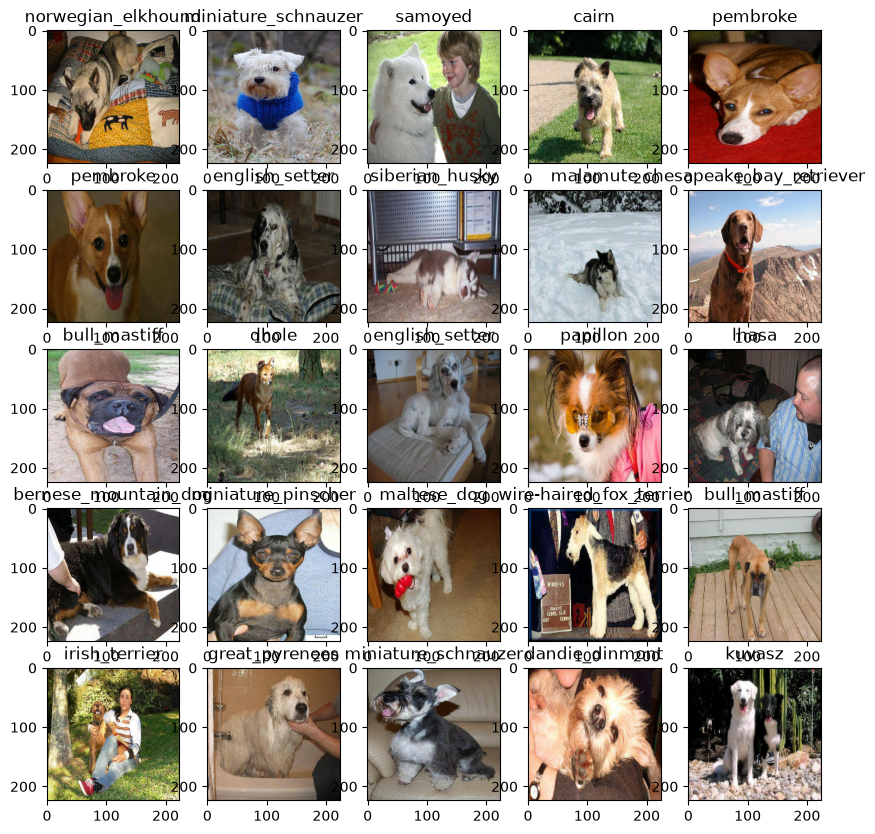

In [44]:
train_images, train_labels = next(train_data.as_numpy_iterator())
show_25_images(train_images, train_labels)

#### **Notice that each time we run the code, the images shuffle themselves; that's bcos in the fc we created we actually shuffled them evrytime they are displayed**

## **Now let's visualize our validation set**

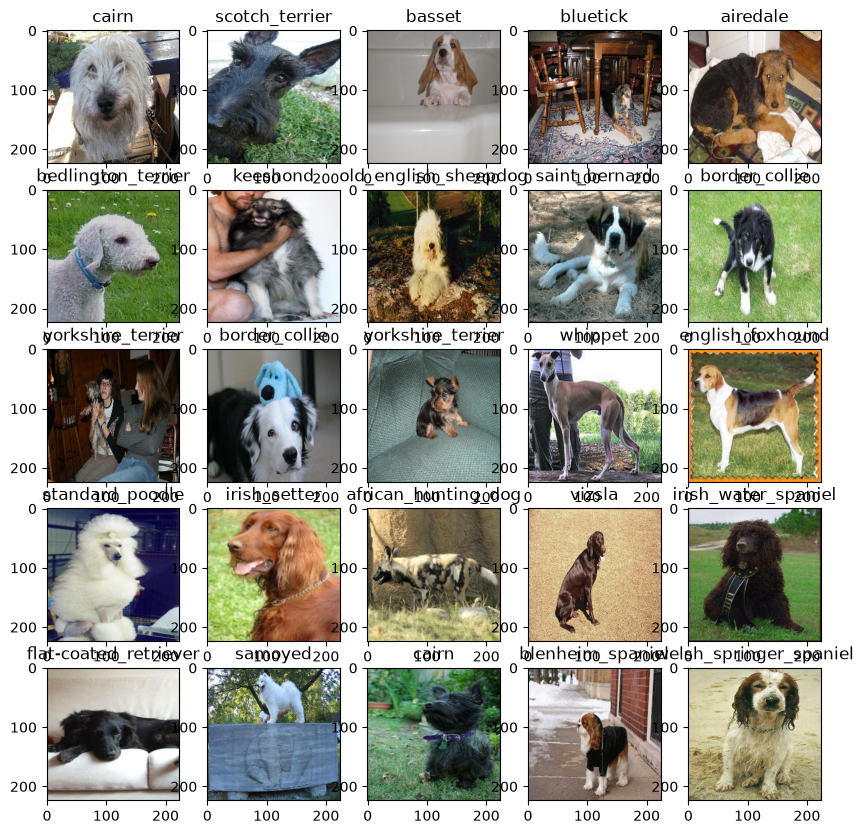

In [45]:
val_images, val_labels = next(val_data.as_numpy_iterator())
show_25_images(val_images, val_labels)

#### **Notice that each time we run the code, the images remain the same; that's bcos in the fc we created we actually did not want the validation data set to be shuffled everytime they are displayed**

# **023 Preparing Our Inputs and Outputs**

## **Building a model**

### **B4 we build a model, there a few things we need to define:**
* #### **The input shape (our images shape, in the form of Tensors) to our model.**
* #### **The output shape (image labels, in the form of Tensors) of our model**
* #### **he URL of the model we want to use from TensorFlow Hub - https://www.kaggle.com/models/google/mobilenet-v2/tensorFlow2/130-224-classification/1?tfhub-redirect=true**

#### **1) Setup the input shape to the model**

In [46]:
INPUT_SHAPE = [None, IMG_SIZE, IMG_SIZE, 3] # batch size, height, width, color channels
# None - the batch size can vary. For example, a batch might contain 
# 32 images, while the last batch might contain fewer.

#### **2) Setup output shape of our model**

In [47]:
OUTPUT_SHAPE = len(unique_breeds)
# This is correct. Your dog-breed dataset contains 120 unique breeds, so the model needs 120 
# output values for each image—one for each possible breed.

#### **3) Setup model URL from TensorFlow Hub**
#### TensorFlow Hub is a library for the publication, discovery, and consumption of reusable parts of ML models. A module is a self-contained piece of a TensorFlow graph along with its weights and assets (a.k.a patterns the previous model has learned), that can be across difft tasks in a process known as transfer learning. Tranfer learning can:
* #### Train a model with a smaller dataset
* #### Improve generalization, and
* #### Speed up training

#### For this our project, we will be using **`MobleNet v2 (imagenet/mobilenet_v2_130_224) Image classification`**.

#### MobileNet v2 is a family of neural network architectures for efficient on-device image classification and realted tasks.

### Now Ask chatgpt when going thru this notebook, about `pytorch` and other places like `TensorFlow Hub` that can be used (ask which is more efficient). And also is transfered learning used more? Also what is the exact work thru to perfroming deep learning, not just image classification, but all round

In [48]:
# MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4"
MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/feature_vector/4"

#### **Chatgpt** said the right model i shuld use here is `MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/feature_vector/4"`. 

#### **The Reasons being:**
#### The feature-vector model is designed for transfer learning: MobileNetV2 extracts features, and your new Dense layer learns to classify those features into your 120 dog breeds.

#### The classification version still outputs scores for its original ImageNet categories before passing them to your new Dense layer. Although the dimensions are compatible, this is not the standard feature-extraction approach.

#### **So keep:** MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/feature_vector/4"

# **026 Building A Deep Learning Model 2**
### There are many ways of building a model in TensorFlow, but one of the best ways to get started is to use the **`TensorFlow Keras API`**

### **`TensorFlow Keras API (tf.keras)` is TensorFlow's high-level API for building and training deep learning models. It's used for fast prototyping state-of-the-art research, and production, with 3 key advantages:**
* ***User-friendly:***
> #### Keras has a simple, consistent interface optimized for common use cases. It provides clear and actionable feedback for user errors
* ***Modular and composable***
> #### Keras models are made by connecting configurable building blocks together, with a few restrictions.
* ***Easy to extend***
> #### Write customm building blocks to express new ideas for research. Create new layers, metrics, loss fcs, and develop state-of-the-art models.

### **Now we've got our inputs, outpus and model ready to go. Let's now put them together into a Keras deep learning model!**

### **Knowing this, let's  create a fc which:**
* #### Takes the the input shape, output shape and the model we've chosen as parameters
* #### Defines the layers in Keras model in sequential fashion (do this first, then this, then that)
* #### Compiles the model (says it should be evaluated and improved)
* #### Builds the model (tells the model the input shape it'll be getting)
* #### Returns the model

### All of the above steps can be found here: https://www.kaggle.com/models/google/mobilenet-v2/tensorFlow2/130-224-classification/1?tfhub-redirect=true

In [49]:
# Create a fc which builds a Keras model
def create_model(input_shape=INPUT_SHAPE, output_shape=OUTPUT_SHAPE, model_url=MODEL_URL):
    # The function accepts three parameters:
    # - input_shape: the shape of the images entering the model.
    # - output_shape: the number of dog breeds the model should predict.
    # - model_url: the location of the pretrained MobileNetV2 model.
    # The default values mean you can call create_model() without supplying the arguments each time.
    print("Building model with: ", model_url)

    # 1) Setup the model layers
    model = tf_keras.Sequential([
        hub.KerasLayer(model_url), # Layer 1 (input layer)
        tf_keras.layers.Dense(units=output_shape,
                             activation="softmax") # Layer 2 (output layer)
    ])
    # A few important points:
    # - hub.KerasLayer(model_url) loads the pretrained model from TensorFlow Hub.
    # - Dense(units=output_shape) creates the output layer with 120 units.
    # - activation="softmax" converts the outputs into class probabilities. The breed with the highest 
    # probability becomes the prediction.

    
    # 2) Compile the model
    model.compile(
        loss=tf_keras.losses.CategoricalCrossentropy(),
        optimizer=tf_keras.optimizers.Adam(),
        metrics=["accuracy"]
    )
    # Compilation tells the model how it will learn and how its performance will be measured.
    # - Loss: CategoricalCrossentropy() measures how far the predictions are from the correct labels. It
    #  is appropriate for one-hot-encoded labels such as the Boolean label arrays you created earlier, 
    #  converted to numerical values.
    # - Optimizer: Adam() adjusts the model's trainable weights to reduce the loss.
    # - Metric: accuracy measures the proportion of predictions that are correct.

    # 3) Build the model
    model.build(input_shape=input_shape)
    # This tells Keras the shape of the input it should expect and allows it to build the model's 
    # variables. Your input shape is: [None, 224, 224, 3]

    return model

In [50]:
model = create_model()
model.summary()

Building model with:  https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/feature_vector/4



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1664)              3766048   
                                                                 
 dense (Dense)               (None, 120)               199800    
                                                                 
Total params: 3965848 (15.13 MB)
Trainable params: 199800 (780.47 KB)
Non-trainable params: 3766048 (14.37 MB)
_________________________________________________________________


 ## **ChatGpt helped me with the issue i had with the code above. An error occurred because my TensorFlow Hub layer and my Keras model were using different versions of the Keras API.**

# **027 Building A Deep Learning Model 3**

### In this lecture, Daniel explains what goes on in  **`Setup the model layers`** above

# **028 Building A Deep Learning Model 4**

### In this lecture, Daniel explains what goes on in  **`Compile the model` and `Build the model`** above

# **029 Summarizing Our Model**
### In this lecture, Daniel explains what goes on in  **`create_model()` and `model.summary()`** above

# **030 Evaluating Our Model**

### **Creating callbacks**
#### Callbacks are helper fcs a model can use during training to do such things as: save it's progress, check its progress or stop training early if a model stops improving.

#### We'll create two callbacks, one for TensorBoard which helps track our models progress and another for early stopping which prevents our model from training for too long.

### **TensorBoard Callback**
### To setup a TensorBoard callback, we need to  do 3 things:
1. #### Load the TensorBoard notebook extensions
2. #### Create a TensorBoard callback which is able to save logs to a directory and pass it to our model's `fit()` fc.
3. #### Visualize our model's training logs with the `%tensroBoard` magic fc (we'll do this after model training)

### **1) Load TensorBoard notebook extension**

In [51]:
# %pip install tensorboard

In [52]:
%load_ext tensorboard

In [53]:
import datetime

### **2) Create a fc to build a TensorBoard callback**
#### This below is how I created the **`logs`** folder in kaggle. Daniel created his just like u will do on VSC

In [54]:
import os

# Create a logs folder inside your project directory
os.makedirs("logs", exist_ok=True)

print("Logs folder created successfully!")

Logs folder created successfully!


### **Tensorboard callback fc**

In [55]:
def create_tensorboard_callback():
    # Create a log directory for storing TensorBoard logs
    logdir = os.path.join(
        "logs",
        # os.path.join("logs", ...) creates a path inside your project's logs folder.
        
        # Make it so the logs get tracked whenevr we run an expirement
        datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
        # datetime.datetime.now().strftime("%Y%m%d-%H%M%S") generates a timestamp, such as 20261022-101530.
    )

    print(f"Saving TensorBoard log files to: {logdir}") # I added this i.e Temple
    
    return tf_keras.callbacks.TensorBoard(logdir)
    # creates a callback that records training information, such as loss and accuracy, while your 
    # model trains.

# **031 Preventing Overfitting**
## **Early stopping callback**
### Early stopping helps stop our model from overfitting by stopping training if a certain evaluation metrics stops improving. https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping

### **3) Create Early stopping callback**

In [56]:
early_stopping = tf_keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3
)

# **032 Training Your Deep Neural Network**

### **Training a model (on subset of data)**
#### Our 1st model is only going to train on 1000 images, to make sure everything is working, b4 we spend time working on 10000 images bcos training on 1000 images will exexcute faster than 10000 images.

In [57]:
NUM_EPOCHS = 100 #@param {type:"slider", min:10, max:100, step:10}

# The above is how u do it in colab, which Daniel used in the course

### **We do it in jupyter notebook this way:**

In [58]:
NUM_EPOCHS = 100 
# we declare it whenever we want to change the nNUM_EPOCHS b4 the code that accompanies it

## **Check to make sure we're still running on a GPU for fast modeling**
### I am using CPU to first create my model on 1000 dataset, after which i use a GPU in kaggle or colab to train the full set, so i dont expect a yes

In [59]:
print("GPU", "available (YESSS!!!!!)" if tf.config.list_physical_devices("GPU") else "not available :(")

GPU not available :(


## **Let's create a fc which trains a model**
* ### Create a model using **`create_model()`**
* ### Setup a TensorBoard callback using create_tensorboard_callback()
* ### Call the `fit` fc on our model passing it the training data, validation data, number of epochs to train for (**`NUM_EPOCHS`**) and the callbacks we'd like to use
* ### Return the model

### **1) Build a fc to train and return a trained model**

In [60]:
def train_model():
    """
    Trains a given model and returns the trained version
    """
    # Create a model
    model = create_model()

    # Create new TensorBoard session everytime we train a model
    tensorboard = create_tensorboard_callback()

    # Fit the model to the data passing it the callbacks we created
    model.fit(
        x=train_data, # Supplies the training batches containing images and labels.
        epochs=NUM_EPOCHS, # Allows training for up to 100 epochs.
        validation_data=val_data, # Evaluates the model using validation batches.
        validation_freq=1, # Runs validation after every epoch.
        callbacks=[tensorboard, early_stopping] # Records metrics and monitors when training should 
        # stop early.
    )

    # Return the fitted model
    return model

### **2) Fit the model to the data**

In [61]:
# model = train_model() # I commented it bcos i have saved the model

Building model with:  https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/feature_vector/4
Saving TensorBoard log files to: logs\20261024-123913
Epoch 1/100



25/25 [==============================] - 25s 799ms/step - loss: 4.2095 - accuracy: 0.1637 - val_loss: 3.1453 - val_accuracy: 0.3800
Epoch 2/100
25/25 [==============================] - 19s 744ms/step - loss: 1.4161 - accuracy: 0.7713 - val_loss: 1.8905 - val_accuracy: 0.6100
Epoch 3/100
25/25 [==============================] - 17s 687ms/step - loss: 0.5341 - accuracy: 0.9525 - val_loss: 1.4639 - val_accuracy: 0.6350
Epoch 4/100
25/25 [==============================] - 21s 855ms/step - loss: 0.2614 - accuracy: 0.9912 - val_loss: 1.2720 - val_accuracy: 0.6800
Epoch 5/100
25/25 [==============================] - 19s 755ms/step - loss: 0.1649 - accuracy: 0.9975 - val_loss: 1.2192 - val_accuracy: 0.6950
Epoch 6/100
25/25 [==============================] - 19s 765ms/step - loss: 0.1166 - accuracy: 1.0000 - val_loss: 1.1781 - val_accuracy: 0.6800
Epoch 7/100
25/25 [==============================] - 21s 832ms/step - loss: 0.0883 - accuracy: 1.0000 - val_loss: 1.1389 - val_accuracy: 0.7000
Epoc

In [62]:
model.save("dog_vision_model.h5")

C:\Users\HP\miniconda3\envs\dog-vision\Lib\site-packages\tf_keras\src\engine\training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


### The reason i saved using **`model.save("dog_vision_model.h5")`** is so that the trained model can make new predictions. The below show the diff btw the way i saved it and pickle saving format:
- #### **dog_vision_model.h5 — the trained model, which can make new predictions.**
- #### **dog_vision_predictions.pkl — the predictions already made on your validation data.**

In [63]:
loaded_model = tf_keras.models.load_model(
    "dog_vision_model.h5",
    custom_objects={"KerasLayer": hub.KerasLayer},
    compile=False
)

In [64]:
loaded_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer_1 (KerasLayer)  (None, 1664)              3766048   
                                                                 
 dense_1 (Dense)             (None, 120)               199800    
                                                                 
Total params: 3965848 (15.13 MB)
Trainable params: 199800 (780.47 KB)
Non-trainable params: 3766048 (14.37 MB)
_________________________________________________________________


## **Our Model is Overfitting. And this is a good thing bcos it shows our model is learning**

# **033 Evaluating Performance With TensorBoard**
### **Checking the TensorBoard logs**
#### The TensorBoard magic fc (%tensorboard) will access the logs directory we created earlier and visualize its contents.

In [65]:
# !taskkill /PID 11604 /F

%load_ext tensorboard
%tensorboard --logdir "logs" --port 6006

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 11052), started 1 day, 3:21:56 ago. (Use '!kill 11052' to kill it.)

## The dark line is the `training dataset accuracy`, while the light blue line is the `validation dataset accuracy`. 

# **Understanding Overfitting, Training Loss and Validation Loss**

#### **Overfitting** occurs when a model learns the training data extremely well but performs considerably worse on unseen data.

### **How to identify overfitting:**
- #### Training accuracy is very high (close to 100%), while validation accuracy is much lower.
- #### Training loss becomes very low, while validation loss remains much higher.
- #### A classic sign is when training loss continues to decrease while validation loss starts increasing.

### **Training loss:** Measures how wrong the model's predictions are on the training data. It helps us monitor how well the model is learning from the examples it trains on.

### **Validation loss:** Measures how wrong the model's predictions are on separate validation data. It helps us assess whether the model's learning generalises to images it has not trained on.

## **Why do we need both?**

#### Training loss alone can make a model look excellent even when it performs poorly on unseen images. Comparing training and validation losses helps us detect overfitting and decide when to stop training.

### **In my Dog Vision project:** Training accuracy reached 100% by Epoch 7, while validation accuracy was about 70% by Epoch 20. Training loss fell to approximately 0.0165, while validation loss remained around 1.0732. 

### **This large gap suggests **`overfitting`** because the model fits the training images much better than the validation images.**

# **034 Make And Transform Predictions**

## **Making and evaluating predictions using a  trained model** 
### **Make predictions on the validation data (not used to train)** 

In [66]:
val_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [67]:
predictions = model.predict(val_data, verbose=1)
# verbose means when making predictions show me ur progress
predictions

7/7 [==============================] - 5s 514ms/step


array([[9.9218311e-04, 1.3192535e-04, 2.5700557e-04, ..., 1.0193186e-04,
        5.2293581e-05, 2.5310176e-03],
       [2.4324076e-03, 1.1706807e-03, 1.3857405e-02, ..., 6.8540574e-04,
        1.3746833e-03, 3.6690084e-04],
       [5.2710634e-06, 7.3823241e-05, 4.4534212e-05, ..., 7.9358672e-04,
        4.0580271e-05, 2.3037146e-04],
       ...,
       [1.6619984e-05, 1.4012292e-04, 1.3308146e-04, ..., 5.8708854e-05,
        3.5455963e-04, 1.0365759e-04],
       [5.6374813e-03, 1.8518386e-04, 3.7180912e-04, ..., 2.3923411e-04,
        1.2536695e-04, 4.4261017e-03],
       [2.1632282e-04, 1.3949283e-05, 1.8224348e-03, ..., 1.7300662e-02,
        1.2122748e-03, 1.5001014e-04]], shape=(200, 120), dtype=float32)

In [68]:
predictions[0] 
# The below is an associated probability for the likeliness for what our 
# model thinks an image is. There is a probability below for every single 
# label. and it is for one image i.e the 1st image in the validation data
# The highest value is going to correspond to the index of the label that 
# the model thinks i most likely.

array([9.9218311e-04, 1.3192535e-04, 2.5700557e-04, 3.2111711e-05,
       8.5299587e-05, 2.4082701e-06, 3.9460242e-02, 1.4899654e-04,
       4.0428466e-05, 1.9146356e-04, 1.1585230e-04, 5.3543030e-05,
       1.3880067e-05, 1.1648241e-05, 1.4882286e-04, 9.7196367e-05,
       1.4653017e-05, 2.8033403e-01, 1.5136987e-06, 2.7278937e-05,
       5.0838257e-04, 2.3609765e-04, 8.2334382e-06, 6.3323136e-04,
       2.0970822e-06, 9.7970114e-06, 2.5319323e-01, 3.1571864e-05,
       7.8776939e-04, 2.8322398e-04, 3.0983970e-04, 1.3199286e-03,
       1.9124166e-04, 4.2308220e-05, 2.9854946e-05, 4.1421689e-02,
       3.0783762e-05, 8.0145139e-05, 7.4632385e-06, 1.7069095e-05,
       1.9402515e-04, 7.4594354e-05, 2.7477816e-05, 8.4121057e-06,
       1.4961501e-05, 2.8263858e-05, 3.3722790e-05, 9.7990640e-05,
       4.0534665e-05, 2.6229257e-04, 9.3635153e-06, 1.0620752e-05,
       1.0708085e-03, 1.3810187e-06, 1.3048957e-05, 1.8790084e-05,
       2.3448441e-05, 6.9587729e-03, 6.0953535e-05, 7.6458044e

## The above is an associated probability for the likeliness for what our model thinks an image is. There is a probability above for every single label. And it is for one image i.e the 1st image in the validation data.The highest value is going to correspond to the index of the label that the model thinks i most likely.

### **Suming everything will give us smth close to 1**

In [69]:
np.sum(predictions[0])

np.float32(1.0)

In [70]:
np.sum(predictions[1])

np.float32(1.0000001)

In [71]:
predictions.shape

(200, 120)

In [72]:
len(y_val)

200

## **First prediction**

In [73]:
index = 0 # This is selecting one prediction

print(predictions[index]) # his prints the 120 probability scores for the first image.
print(f"Max value (probability of prediction): {np.max(predictions[index])}")# Find the highest 
# probability
print(f"Sum: {np.sum(predictions[index])}") # Check the sum of probabilities
print(f"Max index: {np.argmax(predictions[index])}") # np.argmax() returns the index of the largest 
# score.
print(f"Predicted label: {unique_breeds[np.argmax(predictions[index])]}") # Convert that position 
# into a breed name. This uses index 66 to look up the corresponding breed in unique_breeds.

[9.9218311e-04 1.3192535e-04 2.5700557e-04 3.2111711e-05 8.5299587e-05
 2.4082701e-06 3.9460242e-02 1.4899654e-04 4.0428466e-05 1.9146356e-04
 1.1585230e-04 5.3543030e-05 1.3880067e-05 1.1648241e-05 1.4882286e-04
 9.7196367e-05 1.4653017e-05 2.8033403e-01 1.5136987e-06 2.7278937e-05
 5.0838257e-04 2.3609765e-04 8.2334382e-06 6.3323136e-04 2.0970822e-06
 9.7970114e-06 2.5319323e-01 3.1571864e-05 7.8776939e-04 2.8322398e-04
 3.0983970e-04 1.3199286e-03 1.9124166e-04 4.2308220e-05 2.9854946e-05
 4.1421689e-02 3.0783762e-05 8.0145139e-05 7.4632385e-06 1.7069095e-05
 1.9402515e-04 7.4594354e-05 2.7477816e-05 8.4121057e-06 1.4961501e-05
 2.8263858e-05 3.3722790e-05 9.7990640e-05 4.0534665e-05 2.6229257e-04
 9.3635153e-06 1.0620752e-05 1.0708085e-03 1.3810187e-06 1.3048957e-05
 1.8790084e-05 2.3448441e-05 6.9587729e-03 6.0953535e-05 7.6458044e-02
 1.6507095e-04 2.5159410e-05 5.8653200e-04 7.8888312e-05 6.3565247e-05
 6.6122818e-03 1.1155739e-04 4.4577618e-04 1.6677039e-02 2.9275321e-05
 6.530

In [74]:
index = 42
print(predictions[index])
print(f"Max value (probability of prediction): {np.max(predictions[index])}")
print(f"Sum: {np.sum(predictions[index])}")
print(f"Max index: {np.argmax(predictions[index])}")
print(f"Predicted label: {unique_breeds[np.argmax(predictions[index])]}")

[2.68955300e-05 8.60153013e-05 6.56239063e-05 1.10186547e-05
 1.52181904e-03 5.94661105e-05 8.44645547e-05 3.85576813e-03
 2.54925285e-02 1.96246784e-02 4.99633552e-06 8.05355594e-05
 2.63537862e-04 2.32426217e-03 1.58086361e-03 2.89125880e-03
 1.78266673e-05 1.00196485e-04 3.71551549e-04 5.90402924e-04
 6.62108414e-06 7.38279545e-04 2.15288783e-05 2.96937669e-05
 1.19257774e-02 1.59646279e-05 1.28986103e-05 2.37788467e-04
 3.39699152e-04 4.60631563e-05 4.29438587e-05 1.50803564e-04
 8.00950656e-05 4.43968383e-05 9.80998539e-06 2.68121421e-05
 9.12901669e-05 1.07359505e-04 8.78769933e-05 2.34386504e-01
 2.40259673e-04 2.21456721e-05 1.42544275e-03 3.00012516e-06
 8.02759969e-05 3.68123801e-05 1.71495369e-04 1.69293999e-04
 4.64544837e-06 6.66782318e-04 7.88208272e-05 7.63036587e-05
 3.21625004e-04 1.05454656e-03 3.54733129e-06 7.29515566e-04
 1.83780212e-04 3.18414677e-04 1.24039270e-05 4.39284631e-05
 1.26506566e-04 7.14647467e-05 4.47224556e-06 1.20898672e-04
 6.11103242e-05 2.687406

### **From the above, the higher the value (i.e the closer it is to 1), the more confident  a model is about a certain prediction.**
### The printed above is known as **`confidence intervals`**.
### One mthdlgy of evaluating a model is to say, only give me the predictions of confidence value over **`0.8587085008621216`**

In [75]:
unique_breeds[113]

'walker_hound'

## **So the above is how we convert our prediction probabilities in numeric form, smth that our computer understands to smth that we understand, a predicted label.**

# **035 Transform Predictions To Text**

### Having the above  fclty is great but we want to be able to do it at scale. And it would be even better if we could see the image the prediction is being made on!

### **Note:**
### Prediction probabilities are also known as **`Confidence intervals`**

### **1) Turn prediction probabilities into their respective label (easier to understand)**

In [76]:
def get_pred_label(prediction_probabilities):
    """
    Turns an array of prediction probabilities into a label.
    """
    return unique_breeds[np.argmax(prediction_probabilities)]

    # Your model returns 120 probability scores for each image, one for each dog breed.
    # - np.argmax(prediction_probabilities) finds the index of the highest probability.
    # - unique_breeds[...] uses that index to find the corresponding breed name.
    # - return gives the breed name back.

### **2) Get a predicted label based on an array of prediction probabilities**

In [77]:
pred_label = get_pred_label(predictions[0])
pred_label

# predictions[0] selects the probability scores for the first validation image.
# get_pred_label() converts those scores into a breed name.
# pred_label stores the result.

'border_terrier'

In [78]:
pred_label = get_pred_label(predictions[81])
pred_label

'dingo'

### **Since our validation data is still in a batch dataset, we'l have to unbatchify it to make predictions on the validation images and then compare those predictions to the validation labels (truth labels)**

In [79]:
val_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

### **3) Create a fc to unbatch a batched dataset**

In [80]:
# images_ = []
# labels_ = []

# # Loop thru unbatched data
# for image, label in val_data.unbatch().as_numpy_iterator():
#     # print(image[:1]) ## should be 200
#     # print(label[:1]) ## should be 200
#     images_.append(image)
#     labels_.append(label)


# images_[0], labels_[0]

In [81]:
# get_pred_label(labels_[0])

In [82]:
 # get_pred_label(predictions[0])

## The below code is the same as the above, we just only put it in a fc i.e fc to unbatchify

In [83]:
def unbatchify(data):
    """
    Takes a batched dataset of (image, label) Tensors and returns separate arrays of 
    images and labels
    """
    # 1) First, create two empty lists
    images = []
    labels = []
    

    # 2) Next, process one image and label at a time:
    # Loop thru unbatched data
    for image, label in data.unbatch().as_numpy_iterator(): # data.unbatch() removes the batch grouping.
        # as_numpy_iterator() lets you loop through the individual examples as NumPy arrays.
        
        # print(image[:1]) ## should be 200
        # print(label[:1]) ## should be 200
        
        images.append(image) # Add the image to the list
        labels.append(unique_breeds[np.argmax(label)]) # Convert the actual label into a breed name 
        # and add it to the labels list
    
    return images, labels

### **4) Unbatchify the validation data**

In [84]:
val_images, val_labels = unbatchify(val_data)
val_images[0], val_labels[0]

(array([[[0.29599646, 0.43284872, 0.3056691 ],
         [0.26635826, 0.32996926, 0.22846507],
         [0.31428418, 0.27701408, 0.22934894],
         ...,
         [0.77614343, 0.82320225, 0.8101595 ],
         [0.81291157, 0.8285351 , 0.8406944 ],
         [0.8209297 , 0.8263737 , 0.8423668 ]],
 
        [[0.2344871 , 0.31603682, 0.19543913],
         [0.3414841 , 0.36560842, 0.27241898],
         [0.45016077, 0.40117094, 0.33964607],
         ...,
         [0.7663987 , 0.8134138 , 0.81350833],
         [0.7304248 , 0.75012016, 0.76590735],
         [0.74518913, 0.76002574, 0.7830809 ]],
 
        [[0.30157745, 0.3082587 , 0.21018331],
         [0.2905954 , 0.27066195, 0.18401104],
         [0.4138316 , 0.36170745, 0.2964005 ],
         ...,
         [0.79871625, 0.8418535 , 0.8606443 ],
         [0.7957738 , 0.82859945, 0.8605655 ],
         [0.75181633, 0.77904975, 0.8155256 ]],
 
        ...,
 
        [[0.9746779 , 0.9878955 , 0.9342279 ],
         [0.99153054, 0.99772066, 0.94278

# **036 Visualizing Model Predictions**

### **Now we've got ways to get:** 
* #### prediction labels
* #### Validation label (truth labels)
* #### Validation images

### Let's make some fc to make these all a bit more visualized.

### **So we'll create a fc which:**
* #### Takes an array of prediction probabilities, an array of images and integers.
* #### Convert prediction probabilities to a predicted label
* #### Plot predicted label, its predicted probability, truth label and the target image on a single plot

In [85]:
def plot_pred(prediction_probabilities, labels, images, n=1):
    """
    View the prediction, ground truth and image for sample n
    """
    # prediction_probabilities: the model's probability scores for each image.
    # labels: the actual breed names from the validation dataset.
    # images: the validation images.
    # n=1: the index of the image to display. If you don't supply n, it displays the second image because 
    # Python indexing starts at zero.
    


    
    pred_prob, true_label, image = prediction_probabilities[n], labels[n], images[n]
    # pred_prob: the 120 prediction probabilities for that image.
    # true_label: its actual breed.
    # image: the image itself.

    # Get the pred label
    pred_label = get_pred_label(pred_prob)
    
    # Plot image & remove ticks
    plt.imshow(image) #displays the dog image.
    plt.xticks([]) # removes the horizontal-axis tick marks.
    plt.yticks([]) # removes the vertical-axis tick marks.

    # Change the colour of the title depending on if the prediction is right or wrong
    if pred_label == true_label:
        color = "green"
    else:
        color = "red"
    
    # Change plot title to be predicted, probaaility of prediction and truth label
    plt.title(
        "{} {:2.0f}% {}".format(pred_label,
                                np.max(pred_prob) * 100,
                                true_label
                               ), 
                                color=color
        # {} {:2.0f}% {} are for pred_label, np.max(pred_prob) * 100, and true_label
    )

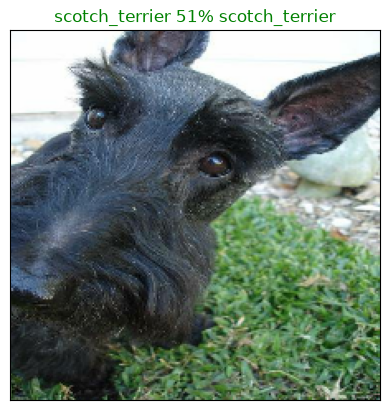

In [86]:
plot_pred(prediction_probabilities=predictions,
         labels=val_labels,
         images=val_images)

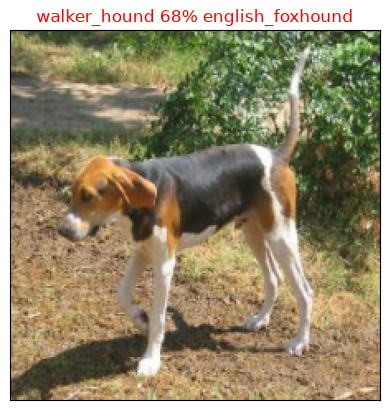

In [87]:
plot_pred(prediction_probabilities=predictions,
         labels=val_labels,
         images=val_images,
         n=42
         )

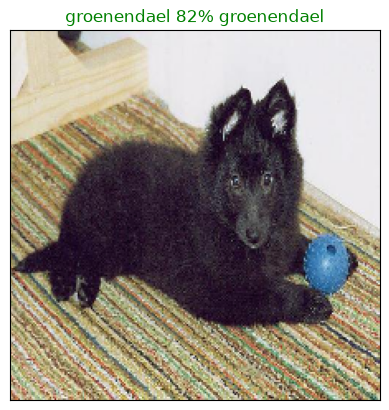

In [88]:
plot_pred(prediction_probabilities=predictions,
         labels=val_labels,
         images=val_images,
         n=77
         )

# **037 Visualizing And Evaluate Model Predictions 2**

### Now we've got one fc to vsiualize our models top prediction, let's make another to view our models top 10 predictions.

### **This fc will:**
* #### Take an input of prediction probabilities array and ground truth array and an integer
* #### Find the prediction using **`get_pred_label()`**
* #### Find the top 10:
    * #### Prediction probabilities indexes
    * #### Prediction probabilities values
    * #### Predicition labels
* #### Plot the top 10 prediction probability values and labels, coloring the true label green

In [89]:
def plot_pred_conf(prediction_probabilities, labels, n=1):
    """
    Plus the top 10 highest prediction confidences along with the truth label for sample n
    """
    pred_prob, true_label = prediction_probabilities[n], labels[n]

    # Get the predicted label
    pred_label = get_pred_label(pred_prob)

    # Find the top 10 prediction confidence indexes
    top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]
    # pred_prob.argsort() returns the indexes of the probability scores arranged from lowest to highest.
    # [-10:] selects the last 10 indexes, which correspond to the 10 highest scores.
    # [::-1] reverses the order i.e eif it was 1, 2, 3, 4 it will be 4, 3, 2, 1

    # Find the top 10 prediction confidence values
    top_10_pred_values = pred_prob[top_10_pred_indexes]

    # Find the top 10 prediction labels
    top_10_pred_labels = unique_breeds[top_10_pred_indexes]

    # Setup plot
    top_plot = plt.bar(
        np.arange(len(top_10_pred_labels)),
        top_10_pred_values,
        color="grey"
    )

    plt.xticks(
        np.arange(len(top_10_pred_labels)), # this means the labels will be seen on the x-axis 
        labels=top_10_pred_labels,
        rotation="vertical",
        
    ) 

    # Change the color  of the true label
    if np.isin(true_label, top_10_pred_labels):
        top_plot[np.argmax(top_10_pred_labels ==true_label)].set_color("green")
    else:
        pass

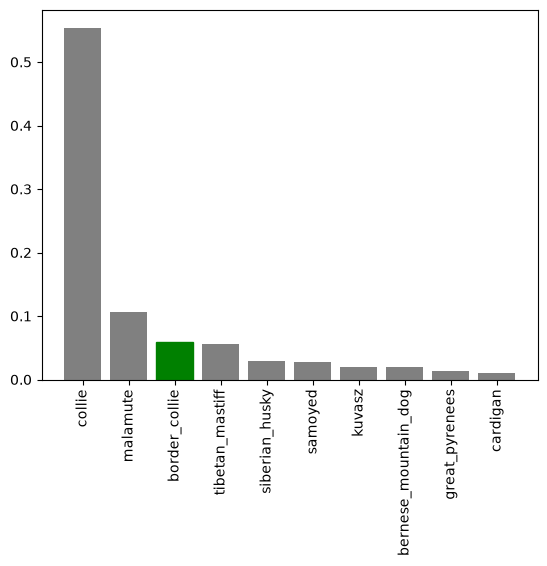

In [90]:
plot_pred_conf(prediction_probabilities=predictions,
               labels=val_labels,
               n=9
              )

# **038 Visualizing And Evaluate  Model Predictions 3**
### Now we've got sm fcs to help us visualize our predictions and evaluate our model, let's check out a few

### **Let's check out a few predictions and their difft values**

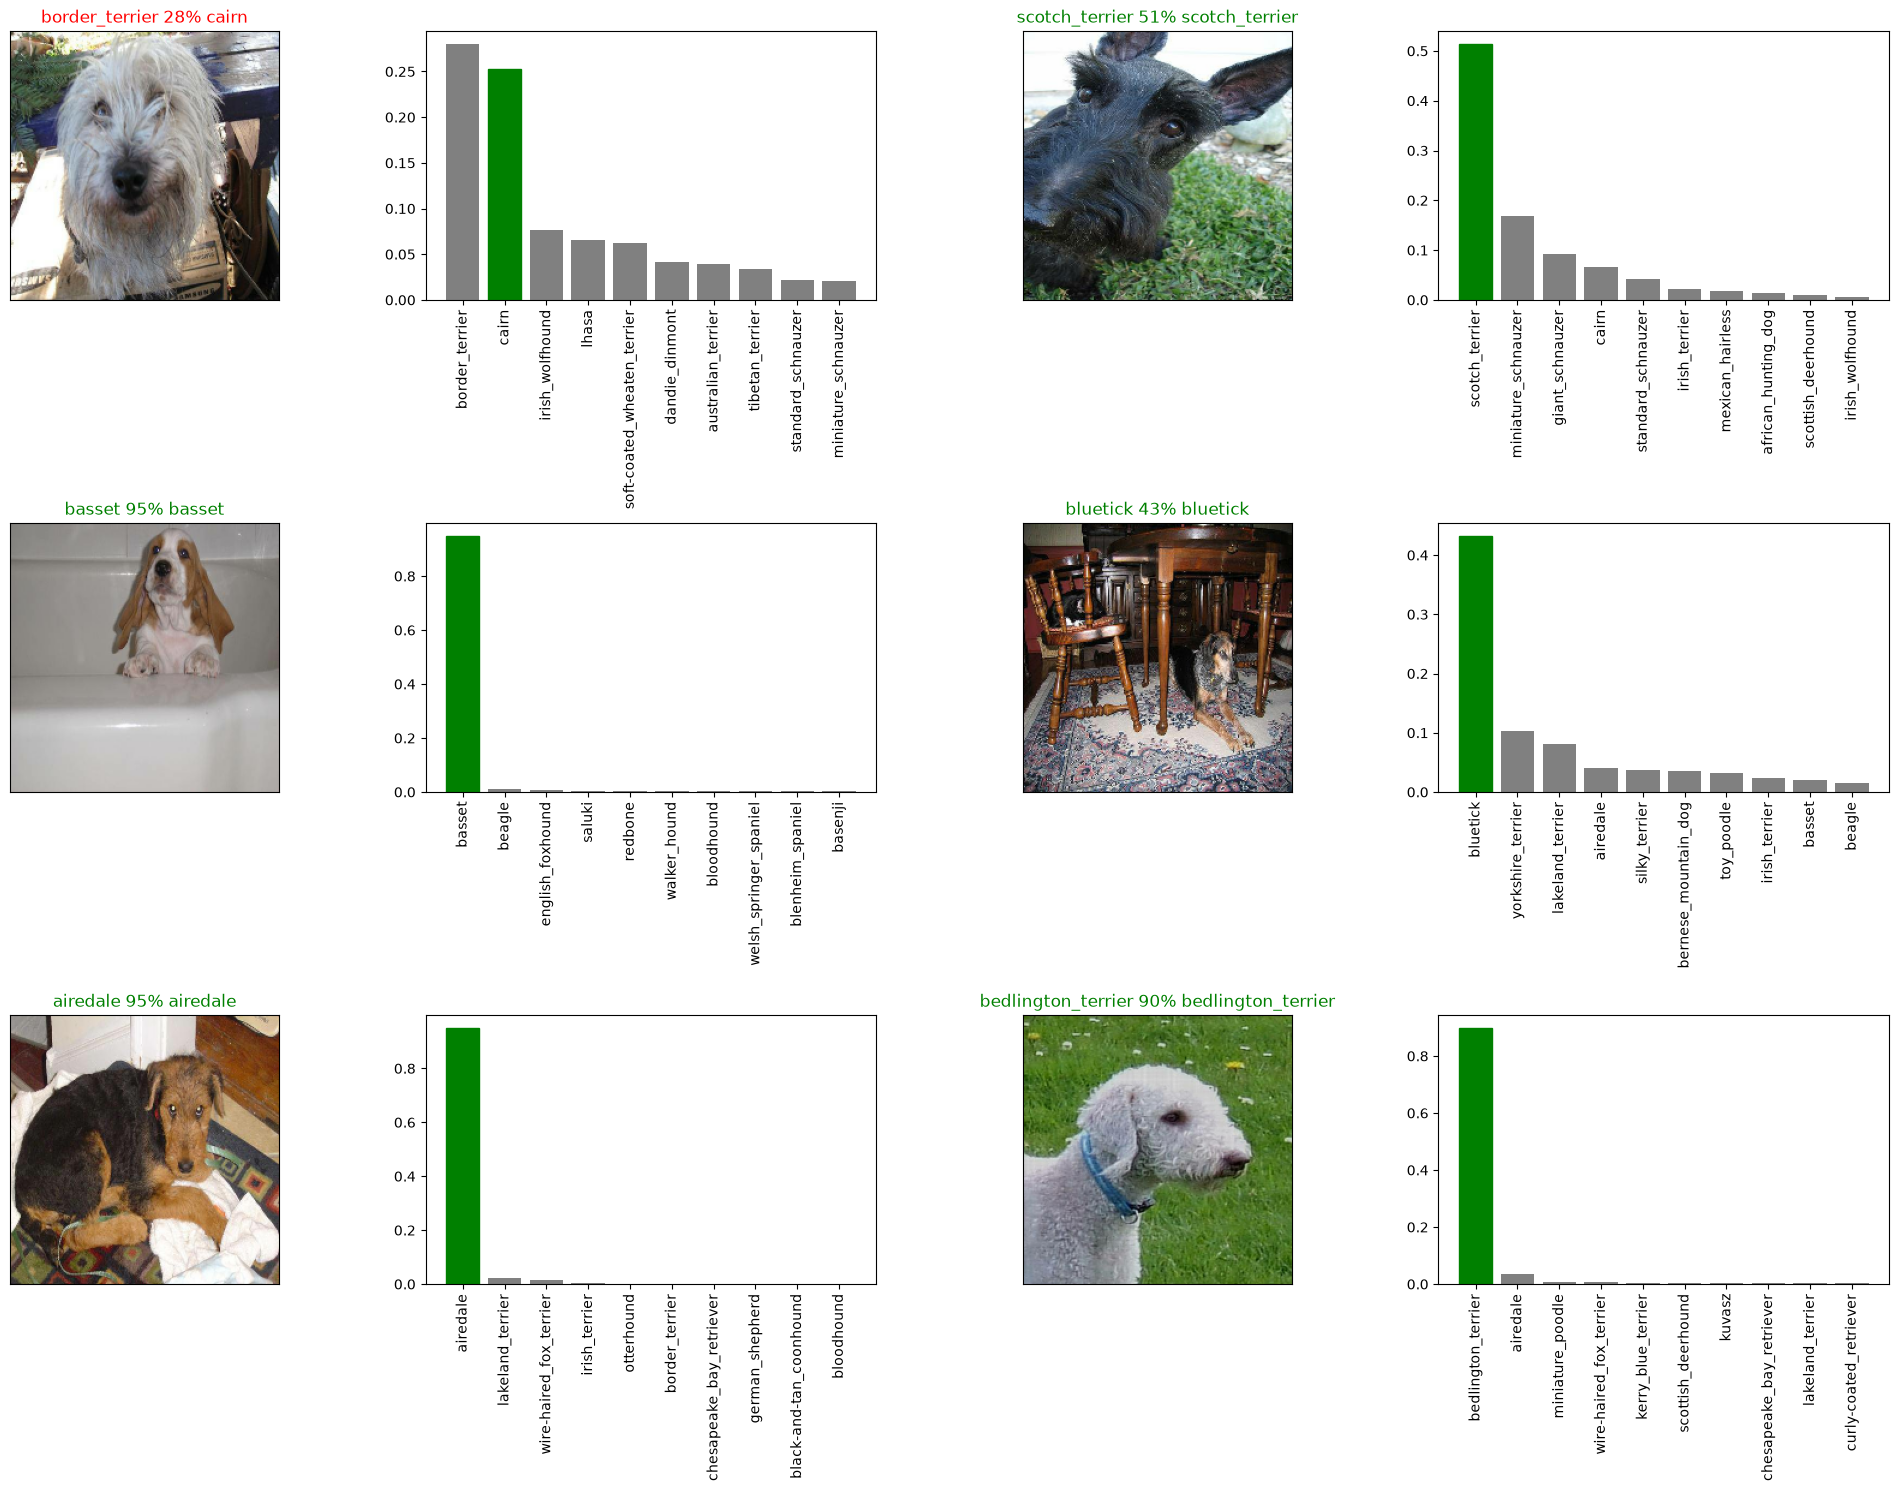

In [91]:
i_multiplier = 0 #starts with validation image index 0
num_rows = 3 # three rows.
num_cols = 2 # two dog images per row.
num_images = num_rows * num_cols # six dog images in total.

plt.figure(figsize=(10 * num_cols, 5 * num_rows)) 

for i in range(num_images):
    plt.subplot(num_rows, 2 * num_cols, 2 * i + 1)
    plot_pred(prediction_probabilities=predictions,
              labels=val_labels,
              images=val_images,
              n=i+i_multiplier
            
             )

    plt.subplot(num_rows, 2 * num_cols, 2 * i + 2)
    plot_pred_conf(prediction_probabilities=predictions,
                   labels=val_labels,
                   n=i+i_multiplier
                  );

plt.tight_layout(h_pad=1.0);  # adjusts the spacing to reduce overlap between plots.
# Use a semi-colon after the last code or use the plt.show() below

plt.show() 

# **039 Saving And Loading A Trained Model**
### We will first create a folder called **`models`** in this directory path **`models`**

In [92]:
import os

# This creates a folder named 'models' inside your writeable directory
os.makedirs("models", exist_ok=True)
print("models folder created successfully!")

models folder created successfully!


### **1) Create a fc to save a model so we can use it for any model**

In [99]:
def save_model(model, suffix=None):
    """
    Saves a given model in a models directory and appends a suffix (string).
    """
    # Create a model directory pathname with current time
    modeldir = os.path.join(
        "models",
        datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    )
    
    # h5 is save format of model (it is an extension)
    model_path = modeldir + "-" + suffix + "h5" 

    print(f"Saving model to: {model_path}...")
    model.save(model_path)

    return model_path 

### **2) Create a fc to load a trained model** 

In [100]:
def load_model(model_path):
    """
    Loads a saved model from a specified path.
    """
    print(f"Loading saved model from: {model_path}")
    
    model = tf_keras.models.load_model(
        model_path,
        custom_objects={"KerasLayer":hub.KerasLayer}
    )

    return model

## **Now we've got fcs to save and load a trained model, let's make sure they work**

### **a) Save our model trained on 1000 images**

In [101]:
save_model(model, suffix="1000-images-mobilenetv2-Adam") 
# The suffix could be anything that will make u remember the model. The suffix is not a
# must, but i find it helpful especially if u want to share it with someone or urself

Saving model to: models\20261024-131039-1000-images-mobilenetv2-Adamh5...
INFO:tensorflow:Assets written to: models\20261024-131039-1000-images-mobilenetv2-Adamh5\assets


INFO:tensorflow:Assets written to: models\20261024-131039-1000-images-mobilenetv2-Adamh5\assets


'models\\20261024-131039-1000-images-mobilenetv2-Adamh5'

### **b) Load a trained model**

In [105]:
loaded_1000_image_model = load_model("models/20261024-131039-1000-images-mobilenetv2-Adamh5")

Loading saved model from: models/20261024-131039-1000-images-mobilenetv2-Adamh5


### **c) Evaluate the pre-saved model**

In [106]:
model.evaluate(val_data)

7/7 [==============================] - 3s 463ms/step - loss: 1.0598 - accuracy: 0.7200


[1.0598489046096802, 0.7200000286102295]

# The above should return the same value as the below

### **d) Evaluate the loaded model**

In [107]:
loaded_1000_image_model.evaluate(val_data)

7/7 [==============================] - 4s 456ms/step - loss: 1.0598 - accuracy: 0.7200


[1.0598489046096802, 0.7200000286102295]

# **040 Training Model On Full Dataset**

## **Training a big dog model (on the full data)**
### It's time to train our model on the full dataset. We have verify that our model is working by going thru checking our model's predictions, evaluating them, and seeing our model is actually learning smth. But since we only trained it on **`a thousand`** images, let's see if we can try in a full scale model like our first full blown deep learning model training on **`10000`** plus images. And this is where the power of the fcs we created earlier are really going to come into play.